In [154]:
from sklearn.datasets import make_classification
import numpy as np

In [155]:
x , y = make_classification(
    n_samples = 100,
    n_features = 2,
    n_informative = 1,
    n_redundant = 0,
    n_classes = 2,
    n_clusters_per_class = 1,
    random_state = 41,
    hypercube = False,
    class_sep = 10
)

In [156]:
import matplotlib.pyplot as plt

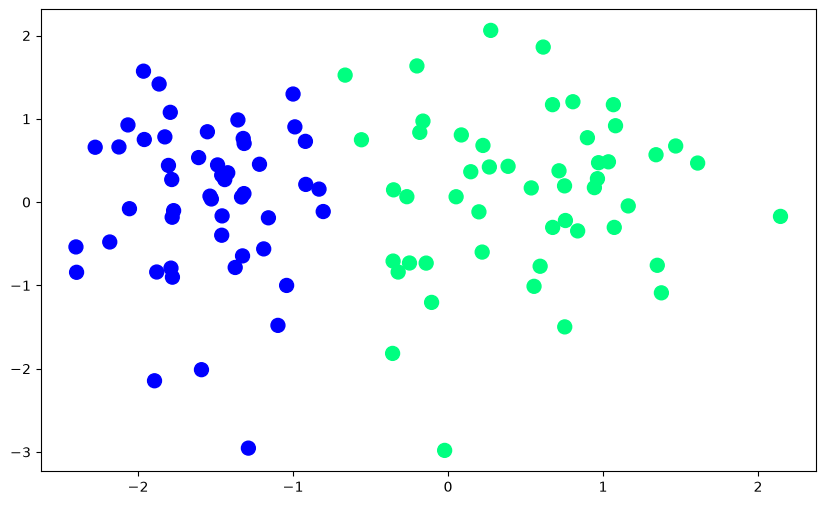

In [157]:
plt.figure(
    figsize = (10, 6)
)

plt.scatter(
    x[ : , 0],
    x[ : , 1],
    c = y,
    cmap = 'winter',
    s = 100
)

plt.show()

### **Code Breakdown from perceptron**

In [158]:
print(x.shape)
print("-----------(x)---------------------")
print(x)
print("-----------(y)---------------------")
print(y)

(100, 2)
-----------(x)---------------------
[[ 0.19924745 -0.11697552]
 [-0.24882029 -0.73115232]
 [-0.3544904  -0.7081059 ]
 [-1.59086506 -2.01199214]
 [-0.20083951  1.63493163]
 [-0.83241122  0.15599044]
 [-1.79207014  1.07782053]
 [ 0.0856607   0.80626713]
 [-0.55865299  0.74859527]
 [-1.95974262  0.75152794]
 [-1.77828947 -0.90114581]
 [-1.77985853 -0.1815243 ]
 [-0.02194151 -2.98092432]
 [ 0.80563431  1.20500136]
 [-1.82701214  0.78302407]
 [ 0.38730728  0.42968688]
 [-0.14108668 -0.73229726]
 [-1.87955941 -0.83930476]
 [-0.18232911  0.83727062]
 [-1.77059533 -0.10255323]
 [-2.27658028  0.65867001]
 [-2.06519502  0.92649819]
 [-1.31690551  0.10216193]
 [ 1.61043259  0.46886454]
 [-1.21650394  0.45432938]
 [ 0.6139723   1.8613386 ]
 [-1.78760957 -0.79255991]
 [-1.04149161 -1.0004391 ]
 [-2.40067584 -0.53814137]
 [-1.80383452  0.44027716]
 [-1.44075613  0.27047889]
 [ 1.34989978 -0.75869267]
 [ 0.22520167  0.6802322 ]
 [ 0.53688527  0.17018845]
 [ 0.55483459 -1.01121977]
 [-0.32178

In [159]:
np.insert(
    x,
    0,
    1,
    axis = 1
)

array([[ 1.        ,  0.19924745, -0.11697552],
       [ 1.        , -0.24882029, -0.73115232],
       [ 1.        , -0.3544904 , -0.7081059 ],
       [ 1.        , -1.59086506, -2.01199214],
       [ 1.        , -0.20083951,  1.63493163],
       [ 1.        , -0.83241122,  0.15599044],
       [ 1.        , -1.79207014,  1.07782053],
       [ 1.        ,  0.0856607 ,  0.80626713],
       [ 1.        , -0.55865299,  0.74859527],
       [ 1.        , -1.95974262,  0.75152794],
       [ 1.        , -1.77828947, -0.90114581],
       [ 1.        , -1.77985853, -0.1815243 ],
       [ 1.        , -0.02194151, -2.98092432],
       [ 1.        ,  0.80563431,  1.20500136],
       [ 1.        , -1.82701214,  0.78302407],
       [ 1.        ,  0.38730728,  0.42968688],
       [ 1.        , -0.14108668, -0.73229726],
       [ 1.        , -1.87955941, -0.83930476],
       [ 1.        , -0.18232911,  0.83727062],
       [ 1.        , -1.77059533, -0.10255323],
       [ 1.        , -2.27658028,  0.658

In [160]:
np.ones(3)

# first 1 is for bias (b), 
# second 1 is for first feature (w1), 
# third 1 is for second feature (w2) 

array([1., 1., 1.])

In [161]:
matrix_of_41th_student = np.insert(x[40], 0, 1)

print(matrix_of_41th_student)
print("-------------------------------------------------------\n")

print("--------Dot product with weights [1, 1, 1] is---------")
dot_product = np.dot(
    matrix_of_41th_student,
    [1 , 1, 1]
)

print("Dot product is: " + str(dot_product))
print("\n-------------------------------------------------------\n")

def step(z):
    return 1 if z >= 0 else 0

step_function_output = step(dot_product)
print("--------Output of step function is---------")
print(step_function_output)



[ 1.         -1.32591376 -0.64584571]
-------------------------------------------------------

--------Dot product with weights [1, 1, 1] is---------
Dot product is: -0.9717594729493686

-------------------------------------------------------

--------Output of step function is---------
0


### **Step Function with z parameter**

In [162]:
def step(z):
    return 1 if z >= 0 else 0

In [163]:
print(step(-1.524))
print(step(1.524))
print(step(0))
print(step(5.524))

0
1
1
1


### **Perceptron**

In [164]:
def perceptron(x, y):
    # ------------------------------------------
    # adding bias to the input features
    # x0 = bias (b) = 1 : first column of x
    # ------------------------------------------
    x = np.insert(
        x,
        0,
        1,
        axis = 1
    )

    # ------------------------------------------
    # w0 = bias (b), 
    # w1 = first feature (w1), 
    # w2 = second feature (w2)
    # ------------------------------------------

    weights = np.ones(
        x.shape[1]
    )

    # ------------------------------------------
    # for transforming the line
    learning_rate = 0.1
    # ------------------------------------------

    epocs = 1000
     
    for i in range(epocs):

        # -----------------------------------------------------------
        # the student we want to choose randomly from the class
        # to check if the student is correctly classified or not
        # means it is in positive region or negative region

        j = np.random.randint(0, 100)
        
        # -----------------------------------------------------------
        # predicting selected student is in positive region or negative region
        y_hat = step(
            np.dot( x[j], weights)
        )

        # new weights = old weights + learning rate * (actual output - predicted output) * input features
        weights = weights + learning_rate * ( y[j] - y_hat ) * x[j]

    # first return value is bias (b), 
    # second return value is weights of features (w1, w2)
    return weights[0], weights[1:]


In [165]:
intercept_, coef_ = perceptron(x, y)

In [166]:
print("intercept_ (b) is: " + str(intercept_))
print("coef_ (w1, w2) is: " + str(coef_))

intercept_ (b) is: 0.9
coef_ (w1, w2) is: [1.42276652 0.04063486]


In [167]:
m = -coef_[0] / coef_[1]
c = -intercept_ / coef_[1]

In [168]:
x_input = np.linspace(-3, 3, 100)
y_input = m * x_input + c

### **Plot**

d:\Rat_Race\AI-ML\env\Lib\site-packages\matplotlib\animation.py:920: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


(-3.0, 2.0)

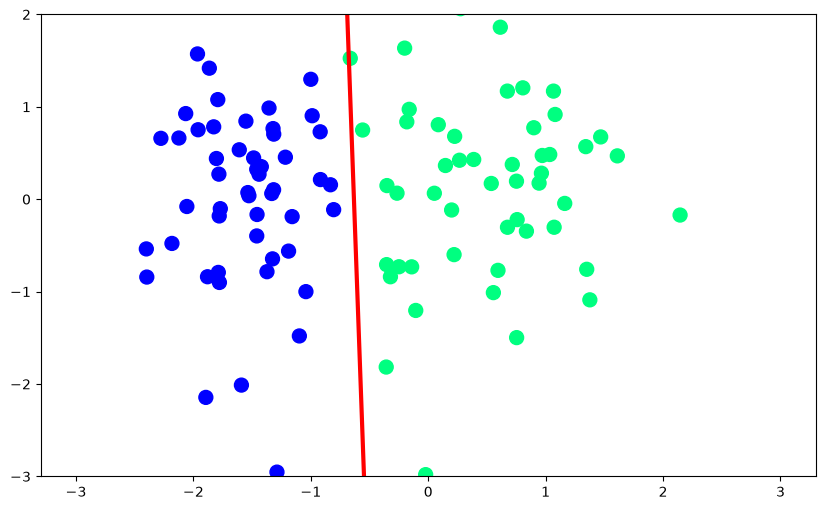

In [169]:
plt.figure(figsize = (10, 6))
plt.plot(
    x_input,
    y_input,
    color = 'red',
    linewidth = 3
)
plt.scatter(
    x[ : , 0],
    x[ : , 1],
    c = y,
    cmap = 'winter',
    s = 100
)
plt.ylim(-3, 2)

### **Animation : no need to learn**

In [170]:
def perceptron(x, y):
    m = []
    b = []

    x = np.insert(
        x,
        0,
        1,
        axis = 1
    )
    weights = np.ones(
        x.shape[1]
    )

    lr = 0.1
    epocs = 200

    for i in range(epocs):
        j = np.random.randint(0, 100)
        y_hat = step(
            np.dot( x[j], weights)
        )
        weights = weights + lr * ( y[j] - y_hat ) * x[j]

        m.append(-weights[1] / weights[2])
        b.append(-weights[0] / weights[2])
    return m, b 

In [171]:
m, b = perceptron(x, y)

In [172]:
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation


In [173]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

fig, ax = plt.subplots(figsize=(9, 5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(
    x[:, 0],
    x[:, 1],
    c=y,
    cmap='winter',
    s=100
)

line, = ax.plot(
    x_i,
    x_i * m[0] + b[0],
    'r-',
    linewidth=2
)

ax.set_ylim(-3, 3)

def update(i):
    line.set_ydata(x_i * m[i] + b[i])
    ax.set_xlabel(f'Epoch {i + 1}')
    return line,

ani = FuncAnimation(
    fig,
    update,
    frames=min(200, len(m), len(b)),
    interval=100,
    blit=True
)

plt.close(fig)
display(HTML(ani.to_jshtml()))